# nucleuswatch quick start

Find this week's nuclear transients, see whether ALeRCE, Fink and Lasair agree on them, and export a Zooniverse subject set.

Lasair needs a free token: `export LASAIR_TOKEN=...` before starting Jupyter. Without it, Lasair is skipped.

## 1. Nuclear transients from the last 14 days

In [1]:
import nucleuswatch as bm

search = bm.nuclear_transients(days=14, cuts=bm.NuclearCuts(mag_max=19))
search.candidates

,object_id,ra,dec,mag,band,mjd,distnr,distpsnr1,sgscore1,ndethist,fink_class,consensus,categories,broker_labels
0,ZTF26acakche,40.261997,-7.499729,17.571490,g,61333.394630,0.418842,0.429463,0.003750,22,SN candidate,agree,SN,alerce:SNIa; alerce:SN; fink:SN candidate
1,ZTF18abxnydk,0.913526,-12.872059,17.624962,r,61331.209780,0.336250,0.416753,0.000000,62,Ambiguous,insufficient,SN,alerce:SN; alerce:SLSN
2,ZTF26ablsebw,5.079298,-9.970565,18.239770,g,61323.216030,0.033137,0.288758,0.149083,165,SN candidate,agree,SN,alerce:SN; alerce:SNII; fink:SN candidate
3,ZTF26abzidlp,304.109184,-1.022193,18.277895,g,61328.224803,0.143532,0.446688,0.029625,17,Early SN Ia candidate,insufficient,SN,alerce:SN; alerce:SLSN
4,ZTF26abypolw,322.172372,3.963319,18.621193,g,61327.191701,0.129398,0.044665,0.012042,26,Ambiguous,insufficient,SN,alerce:SNIa; alerce:SN
5,ZTF26abysngk,20.806673,-3.130521,18.750986,r,61329.267407,0.439631,0.326274,0.001250,31,Ambiguous,insufficient,SN,alerce:SNIa; alerce:SN


In [2]:
search.query  # store this alongside your results

{'recipe': 'nuclear_transients',
 'days': 14,
 'startdate': '2026-10-09',
 'stopdate': '2026-10-24',
 'fink_classes': ['SN candidate',
  'Early SN Ia candidate',
  'SLSN candidate',
  'Ambiguous'],
 'cuts': {'mag_max': 19,
  'distnr_max': 0.5,
  'distpsnr1_max': 1.0,
  'sgscore1_max': 0.5,
  'ndethist_min': 2}}

## 2. Drill into one candidate

In [3]:
obj = search.objects[search.candidates.object_id[0]]
obj.summary()

,broker,ra,dec,offset_arcsec,ndet,first_mjd,last_mjd,url,stellar,simbad
0,alerce,40.261969,-7.499752,0.065204,21,61320.356539,61333.39463,https://alerce.online/object/ZTF26acakche,False,NaN
1,fink,40.261997,-7.499729,0.065204,10,61321.361817,61333.39463,https://fink-portal.org/ZTF26acakche,NaN,Unknown


`votes=True` rows are whole-object labels that count toward consensus. The rest are binary scores or sub-classifiers.

In [4]:
obj.classifications

,broker,classifier,label,probability,version,votes,category
0,alerce,lc_classifier,SNIa,0.333792,lc_classifier_1.1.13,True,SN
1,alerce,LC_classifier_ATAT_forced_phot(beta),SNIa,0.998392,1.0.0,False,NaN
2,alerce,lc_classifier_BHRF_forced_phot,SNIa,0.400896,2.1.0,False,NaN
3,alerce,lc_classifier_BHRF_forced_phot_top,Transient,0.928000,2.1.0,False,NaN
4,alerce,lc_classifier_BHRF_forced_phot_transient,SNIa,0.432000,2.1.0,False,NaN
5,alerce,stamp_classifier,SN,0.833139,stamp_classifier_1.0.4,True,SN
6,alerce,stamp_classifier_2025_beta,AGN,0.507567,2.1.1_beta,False,NaN
7,alerce,lc_classifier_BHRF_forced_phot_periodic,CEP,0.384000,2.1.0,False,NaN
8,alerce,lc_classifier_BHRF_forced_phot_stochastic,CV/Nova,0.600000,2.1.0,False,NaN
9,fink,fink_classification,SN candidate,NaN,9.5.0,True,SN


In [5]:
obj.consensus()

{'status': 'agree',
 'categories': ['SN'],
 'votes': [{'broker': 'alerce',
   'classifier': 'lc_classifier',
   'label': 'SNIa',
   'category': 'SN'},
  {'broker': 'alerce',
   'classifier': 'stamp_classifier',
   'label': 'SN',
   'category': 'SN'},
  {'broker': 'fink',
   'classifier': 'fink_classification',
   'label': 'SN candidate',
   'category': 'SN'}]}

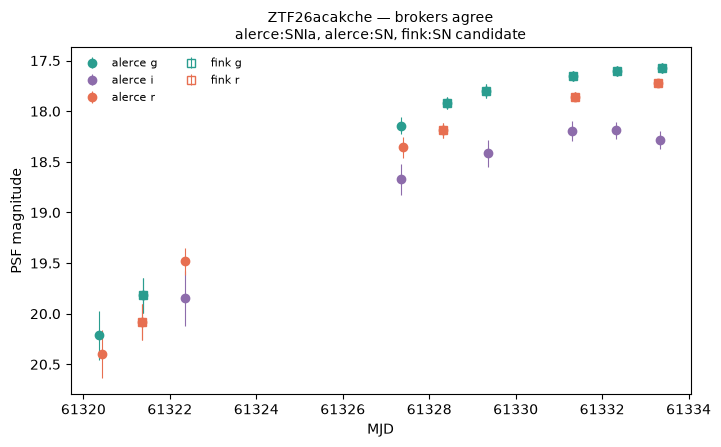

In [6]:
obj.plot();

The volunteer view: no id, no broker labels, days since first detection.

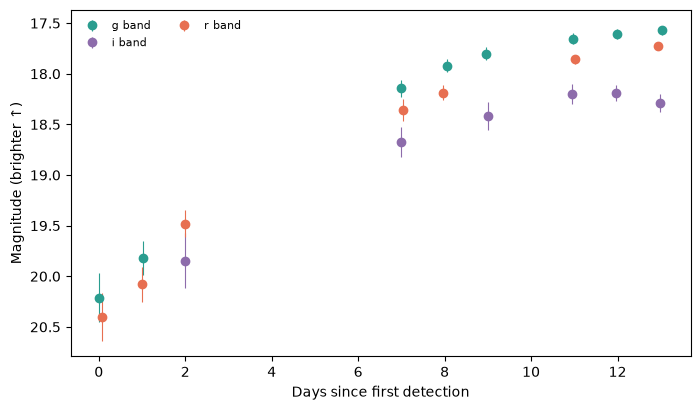

In [7]:
obj.plot(annotate=False);

## 3. Export to Zooniverse

In [8]:
from nucleuswatch.zooniverse import export_subjects, read_manifest
import pandas as pd

path = export_subjects(search, "zooniverse_export")
pd.DataFrame(read_manifest(path)).head()

,image1,image2,!object_id,!ra,!dec,!alerce_url,!fink_url,#consensus,#categories,#n_detections,#peak_mag,#first_mjd,#last_mjd,#brokers,#nucleuswatch_version,#alerce_lc_classifier,#alerce_stamp_classifier,#fink_fink_classification
0,ZTF26acakche_lightcurve.png,ZTF26acakche_stamps.png,ZTF26acakche,40.261969,-7.499752,https://alerce.online/object/ZTF26acakche,https://fink-portal.org/ZTF26acakche,agree,SN,21,17.571,61320.35654,61333.39463,alerce;fink,0.2.0,SNIa,SN,SN candidate
1,ZTF26ablsebw_lightcurve.png,ZTF26ablsebw_stamps.png,ZTF26ablsebw,5.079283,-9.970549,https://alerce.online/object/ZTF26ablsebw,https://fink-portal.org/ZTF26ablsebw,agree,SN,157,17.669,61256.37112,61334.23160,alerce;fink,0.2.0,SNII,SN,SN candidate
2,ZTF26abzidlp_lightcurve.png,ZTF26abzidlp_stamps.png,ZTF26abzidlp,304.109161,-1.022158,https://alerce.online/object/ZTF26abzidlp,https://fink-portal.org/ZTF26abzidlp,insufficient,SN,27,18.154,61318.12763,61334.22946,alerce;fink,0.2.0,SLSN,SN,
3,ZTF18abxnydk_lightcurve.png,ZTF18abxnydk_stamps.png,ZTF18abxnydk,0.913579,-12.872014,https://alerce.online/object/ZTF18abxnydk,https://fink-portal.org/ZTF18abxnydk,insufficient,SN,64,17.486,61297.31478,61334.21047,alerce;fink,0.2.0,SLSN,SN,
4,ZTF26abysngk_lightcurve.png,ZTF26abysngk_stamps.png,ZTF26abysngk,20.806662,-3.130504,https://alerce.online/object/ZTF26abysngk,https://fink-portal.org/ZTF26abysngk,insufficient,SN,42,18.652,61314.45846,61334.29153,alerce;fink,0.2.0,SNIa,SN,


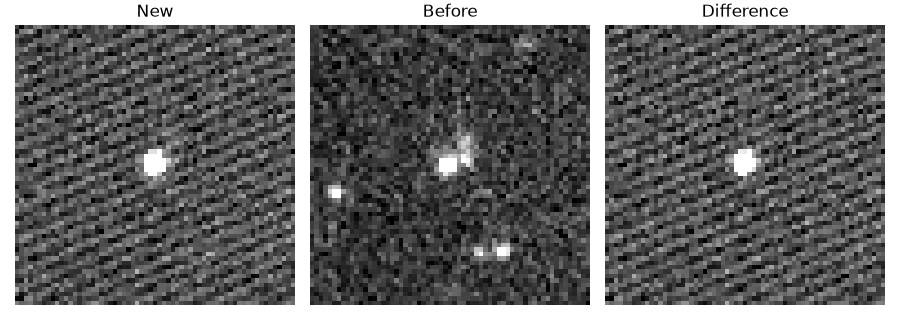

In [9]:
from IPython.display import Image
Image(str(path.parent / read_manifest(path)[0]["image2"]))

Upload with `nucleuswatch zooniverse-upload zooniverse_export --project ID --subject-set NAME`, or drag the folder into the Project Builder.